Method          | Test Accuracy   | Training Time     
-------------------------------------------------------
Batch GD        | 100.00%           | 0.7822 sec
Mini-Batch GD   | 100.00%           | 4.9295 sec
SGD             | 100.00%           | 63.9791 sec


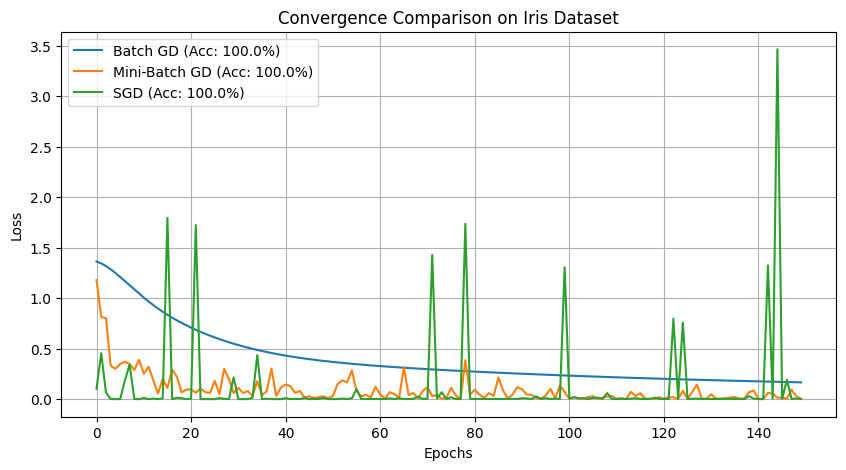

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score


# Load Iris dataset
iris = load_iris()

x = iris.data
y = iris.target


# Train-test split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)


# Standardize features
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

train_size = x_train.shape[0]


# Different batch sizes
configs = {
    "Batch GD": {"batch_size": train_size},
    "Mini-Batch GD": {"batch_size": 16},
    "SGD": {"batch_size": 1}
}


epochs = 150
results = {}


for name, cfg in configs.items():

    clf = MLPClassifier(
        hidden_layer_sizes=(10,),
        activation='relu',
        solver='sgd',
        learning_rate_init=0.01,
        random_state=42
    )

    classes = np.unique(y)
    loss_history = []

    start_time = time.time()

    # Training loop
    for epoch in range(epochs):

        # Shuffle training data
        indices = np.random.permutation(train_size)

        x_shuffled = x_train[indices]
        y_shuffled = y_train[indices]

        batch_size = cfg["batch_size"]

        # Mini-batches
        for i in range(0, train_size, batch_size):

            x_batch = x_shuffled[i:i + batch_size]
            y_batch = y_shuffled[i:i + batch_size]

            clf.partial_fit(
                x_batch,
                y_batch,
                classes=classes
            )

        # Store loss after each epoch
        loss_history.append(clf.loss_)

    # Training time
    elapsed_time = time.time() - start_time

    # Test accuracy
    acc = accuracy_score(
        y_test,
        clf.predict(x_test)
    )

    results[name] = {
        "loss": loss_history,
        "acc": acc,
        "time": elapsed_time
    }


# Print results
print(f"{'Method':<15} | {'Test Accuracy':<15} | {'Training Time':<18}")
print("-" * 55)

for name, res in results.items():

    print(
        f"{name:<15} | "
        f"{res['acc'] * 100:.2f}%{'':<10} | "
        f"{res['time']:.4f} sec"
    )


# Plot loss
plt.figure(figsize=(10, 5))

for name, res in results.items():

    plt.plot(
        res["loss"],
        label=f"{name} (Acc: {res['acc'] * 100:.1f}%)"
    )


plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Convergence Comparison on Iris Dataset")
plt.legend()
plt.grid(True)

plt.show()